<a href="https://colab.research.google.com/github/Vandana-kannan/number-classification/blob/main/Number_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers


In [2]:
mnist = keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
print(x_train.shape)
print(y_train.shape)

print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


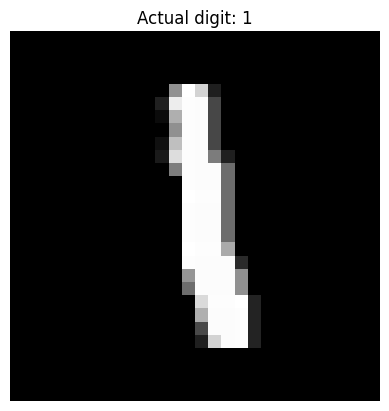

In [6]:
plt.imshow(x_train[6], cmap='gray')
plt.title(f"Actual digit: {y_train[6]}")
plt.axis('off')
plt.show()

In [7]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [8]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

In [9]:
model = keras.Sequential([

    keras.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation='relu'),

    layers.Dense(10, activation='softmax')
])

In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.9431 - loss: 0.1892 - val_accuracy: 0.9810 - val_loss: 0.0666
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9829 - loss: 0.0540 - val_accuracy: 0.9868 - val_loss: 0.0475
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9877 - loss: 0.0392 - val_accuracy: 0.9888 - val_loss: 0.0360
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9911 - loss: 0.0281 - val_accuracy: 0.9905 - val_loss: 0.0333
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9925 - loss: 0.0235 - val_accuracy: 0.9910 - val_loss: 0.0345
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9947 - loss: 0.0169 - val_accuracy: 0.9910 - val_loss: 0.0340
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9955 - loss: 0.0145 - val_accuracy: 0.9898 - val_loss: 0.0421
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9962 - loss: 0.0114 - val_accuracy: 

In [12]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9891 - loss: 0.0367
Test Loss: 0.036700304597616196
Test Accuracy: 0.9890999794006348


In [13]:
predictions = model.predict(x_test)

print("Predicted digit:", np.argmax(predictions[0]))
print("Actual digit:", y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Predicted digit: 7
Actual digit: 7


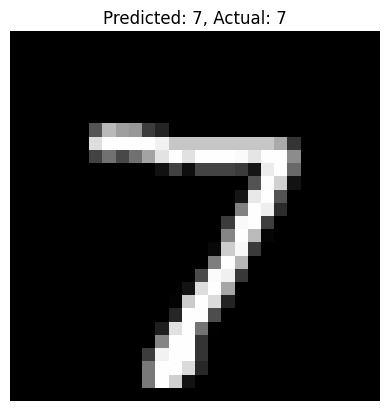

In [14]:
plt.imshow(x_test[0].reshape(28, 28), cmap='gray')

plt.title(
    f"Predicted: {np.argmax(predictions[0])}, "
    f"Actual: {y_test[0]}"
)

plt.axis('off')
plt.show()

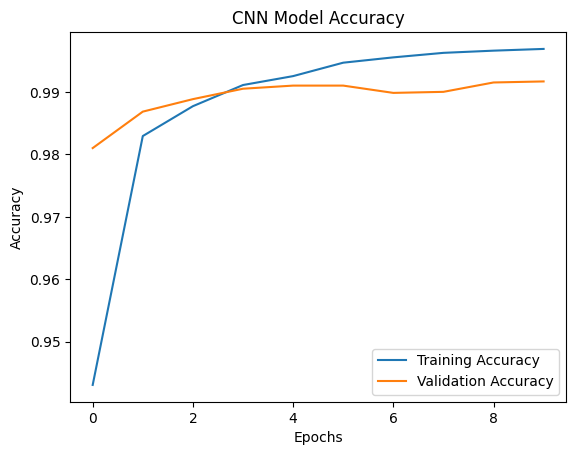

In [15]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('CNN Model Accuracy')

plt.legend()
plt.show()